# This methods are only applicable for data having `normal distribution`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('00 placement.csv')

In [3]:
df.sample(10)

,cgpa,placement_exam_marks,placed
953,6.91,44.0,0
717,6.49,21.0,0
247,6.25,49.0,0
692,6.95,43.0,0
335,6.90,17.0,1
503,6.97,10.0,1
873,7.90,42.0,1
902,7.03,42.0,1
501,6.52,31.0,0
79,7.63,19.0,1


In [4]:
df.shape

(1000, 3)

C:\Users\jugal\AppData\Local\Temp\ipykernel_16768\1806873083.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'], hist = False)
C:\Users\jugal\AppData\Local\Temp\ipykernel_16768\1806873083.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['placement_exam_marks'])


<AxesSubplot: xlabel='placement_exam_marks', ylabel='Density'>

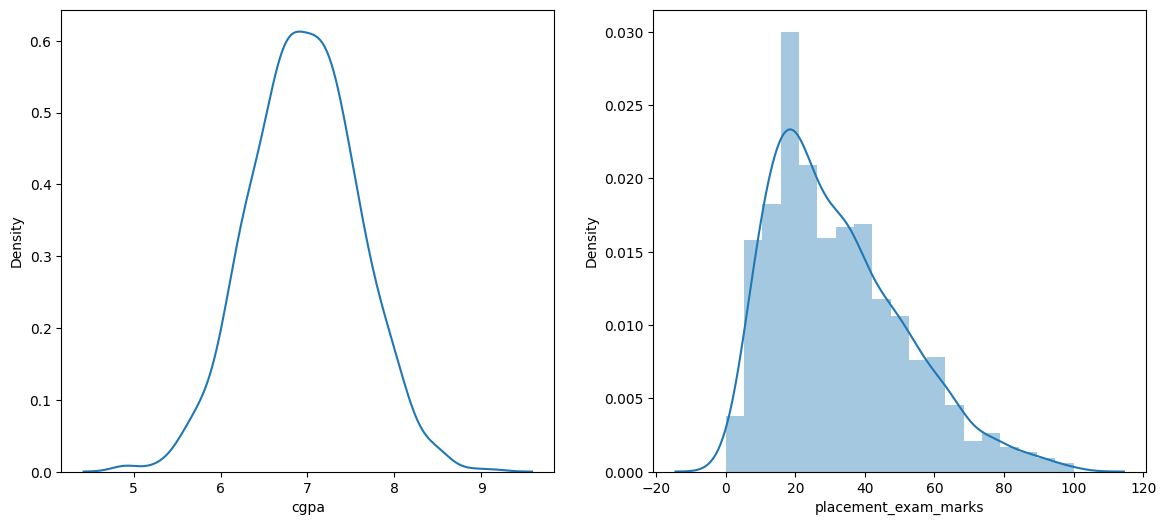

In [6]:
plt.figure(figsize = (14, 6))

plt.subplot(121)
sns.distplot(df['cgpa'], hist = False)

plt.subplot(122)
sns.distplot(df['placement_exam_marks'])

In [8]:
mean_cgpa = df.cgpa.mean()
std_cgpa = df.cgpa.std()
min_cgpa = df.cgpa.min()
max_cgpa = df.cgpa.max()

In [9]:
print(f'Mean of cgpa: {mean_cgpa}')
print(f'Std_dev of cgpa: {std_cgpa}')
print(f'Minimum value of cgpa: {min_cgpa}')
print(f'Maximum value of cgpa: {max_cgpa}')

Mean of cgpa: 6.96124
Std_dev of cgpa: 0.6158978751323896
Minimum value of cgpa: 4.89
Maximum value of cgpa: 9.12


In [10]:
# Finding Lhe boundry points.
# Upper = μ + 3σ
# Lower = μ - 3σ

lower = mean_cgpa - (3* std_cgpa)
upper = mean_cgpa + (3* std_cgpa)

In [12]:
print(f'Lowest allowed: {lower}')
print(f'Highest allowed: {upper}')

Lowest allowed: 5.113546374602832
Highest allowed: 8.808933625397168


In [23]:
# Finding the outliers.

outliers = df[(df['cgpa'] > upper) | (df['cgpa'] < lower)]

In [24]:
outliers

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


# 1) Trimming

In [37]:
# Removing  outliers: We'll keep only those rows whhich are greater than lower boundry and smaller than the upper boundry

trim_df = df[(df.cgpa > lower) & (df.cgpa < upper)]

In [38]:
trim_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
991,7.04,57.0,0
992,6.26,12.0,0
993,6.73,21.0,1
994,6.48,63.0,0


# Trimming using Z-Score.

In [39]:
# Creating a new column containing z-scores if the data points.


z_scores = (df['cgpa'] - mean_cgpa) / std_cgpa

In [40]:
z_scores

0      0.371425
1      0.809810
2      0.939701
3     -0.878782
4      0.436371
         ...   
995    3.099150
996    3.505062
997   -3.362960
998    2.693239
999   -3.346724
Name: cgpa, Length: 1000, dtype: float64

In [41]:
df['cgpa_zscore'] = z_scores

In [42]:
df.head()

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [45]:
# Trimming using Z-Scoore: Values having Z-score less than -3 and more than 3 are considered as outliers

outliers = df[
(df['cgpa_zscore'] < -3) |
(df['cgpa_zscore'] > 3)
]

In [46]:
outliers

,cgpa,placement_exam_marks,placed,cgpa_zscore
485,4.92,44.0,1,-3.314251
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [51]:
# We can see that we are getting the same rows as outliers which we got above.
# so let's remove these outliers by keeping rows with z-score higher than -3 and lesser tahn 3

trim_df2 = df[
(df.cgpa_zscore > -3) &
(df.cgpa_zscore < 3)
]

In [52]:
trim_df2

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371
...,...,...,...,...
991,7.04,57.0,0,0.127878
992,6.26,12.0,0,-1.138565
993,6.73,21.0,1,-0.375452
994,6.48,63.0,0,-0.781363


# 2) Capping

In [56]:
# Upper limit = μ + 3σ
# Lower limit = μ - 3σ

upper_limit = mean_cgpa + (3* std_cgpa)
lower_limit = mean_cgpa - (3* std_cgpa)


In [57]:
print(upper_limit)
print(lower_limit)

8.808933625397168
5.113546374602832


In [64]:
# Creating a new column named 'capped_cgpa' where we'll cap all the five outliers.

df['capped_cgpa'] = np.where(df.cgpa > upper_limit, upper_limit,
                            np.where(df.cgpa < lower_limit, lower_limit, df.cgpa))


'''
np.where() takes three arguments, 1) condition, 2) if condition is true than what to do and
3) if condition is false, then what to do.

In the above code, 'np.where(df.cgpa > upper_limit, upper_limit' upto this, two arguments are already passed, and for 
third argument, we have passed a new np.where() which is 'np.where(df.cgpa < lower_limit, lower_limit, df.cgpa)'

So what it's ultimately doing is, it's checking if the value is > upper limit, if yes then input upper_limit.
If false, then inside new np.where() check if it is < lower limit. If yes, then imput lower limit
and if false then keep it as its is.
'''

"\nnp.where() takes three arguments, 1) condition, 2) if condition is true than what to do and\n3) if condition is false, then what to do.\n\nIn the above code, 'np.where(df.cgpa > upper_limit, upper_limit' upto this, two arguments are already passed, and for \nthird argument, we have passed a new np.where() which is 'np.where(df.cgpa < lower_limit, lower_limit, df.cgpa)'\n\nSo what it's ultimately doing is, it's checking if the value is > upper limit, if yes then input upper_limit.\nIf false, then inside new np.where() check if it is < lower limit. If yes, then imput lower limit\nand if false then keep it as its is.\n"

In [59]:
df

,cgpa,placement_exam_marks,placed,cgpa_zscore,capped_cgpa
0,7.19,26.0,1,0.371425,7.190000
1,7.46,38.0,1,0.809810,7.460000
2,7.54,40.0,1,0.939701,7.540000
3,6.42,8.0,1,-0.878782,6.420000
4,7.23,17.0,0,0.436371,7.230000
...,...,...,...,...,...
995,8.87,44.0,1,3.099150,8.808934
996,9.12,65.0,1,3.505062,8.808934
997,4.89,34.0,0,-3.362960,5.113546
998,8.62,46.0,1,2.693239,8.620000


In [61]:
df.capped_cgpa.describe()

# We can see that std_dev and mean are almost same as before and minimum value is our lower limit
# and maximin value is our  upper limit.

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: capped_cgpa, dtype: float64

In [62]:
# Let's check if there are outliers in capped_cgpa.

df[
(df.capped_cgpa < lower_limit) |
(df.capped_cgpa > upper_limit)
]

,cgpa,placement_exam_marks,placed,cgpa_zscore,capped_cgpa


In [63]:
# We can see there're no outliers present after capping

In [85]:
# Let's see if it actually capped with lower and upper limit or not.

df[
(df['cgpa'] < lower_limit) |
(df['cgpa'] > upper_limit)
]

,cgpa,placement_exam_marks,placed,cgpa_zscore,capped_cgpa
485,4.92,44.0,1,-3.314251,5.113546
995,8.87,44.0,1,3.099150,8.808934
996,9.12,65.0,1,3.505062,8.808934
997,4.89,34.0,0,-3.362960,5.113546
999,4.90,10.0,1,-3.346724,5.113546


# Not needed, just did for my curiosity.

# Without using np.where()

# Note: np.where() is more easier than this

In [65]:
df2 = pd.read_csv("00 placement.csv")

In [66]:
df2

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


In [73]:
capped_cgpa = []

for i in range(len(df2)):
    if df2.cgpa[i] > upper_limit:
        capped_cgpa.append(upper_limit)

    elif df2.cgpa[i] < lower_limit:
        capped_cgpa.append(lower_limit)

    else:
        capped_cgpa.append(df2.cgpa[i])

In [75]:
len(capped_cgpa)

1000

In [78]:
df2['capped_cgpa'] = capped_cgpa

In [79]:
df2

,cgpa,placement_exam_marks,placed,capped_cgpa
0,7.19,26.0,1,7.190000
1,7.46,38.0,1,7.460000
2,7.54,40.0,1,7.540000
3,6.42,8.0,1,6.420000
4,7.23,17.0,0,7.230000
...,...,...,...,...
995,8.87,44.0,1,8.808934
996,9.12,65.0,1,8.808934
997,4.89,34.0,0,5.113546
998,8.62,46.0,1,8.620000


In [84]:
df2.capped_cgpa.describe()

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: capped_cgpa, dtype: float64

# Another way to run the loop(without using range() function)

In [86]:
df3 = pd.read_csv("00 placement.csv")

In [87]:
df3.sample(5)

,cgpa,placement_exam_marks,placed
547,7.33,39.0,0
502,7.18,50.0,1
576,6.12,8.0,1
486,7.67,65.0,1
385,7.33,21.0,0


In [89]:
for value in df3.cgpa:
    print(value)

7.19
7.46
7.54
6.42
7.23
7.3
6.69
7.12
6.45
7.75
6.82
6.38
6.58
5.68
7.91
7.1
6.53
7.56
6.93
7.63
6.69
7.43
6.76
6.05
6.44
6.28
7.45
6.53
7.23
6.51
7.46
7.66
5.91
6.23
8.15
7.48
6.85
8.51
6.58
7.25
6.6
6.7
7.46
7.85
7.88
6.92
7.3
6.92
6.29
8.23
6.2
6.24
7.53
6.69
8.42
8.12
6.93
7.73
7.34
7.7
7.94
7.51
7.61
6.22
6.98
6.27
6.67
8.04
6.58
7.41
6.98
6.13
7.9
6.39
6.16
6.77
8.35
7.1
8.2
7.63
6.87
7.12
7.22
7.38
5.65
6.03
7.19
6.96
6.78
6.56
7.61
7.42
6.48
7.0
7.15
6.89
7.09
7.33
8.12
7.46
6.56
6.48
5.92
6.44
6.82
6.72
6.59
7.32
5.94
7.23
6.96
6.48
7.23
7.24
6.3
7.28
7.16
7.11
6.9
7.0
6.99
5.91
5.97
6.25
6.2
7.46
7.16
6.95
6.76
6.81
5.91
8.19
7.71
7.65
6.33
6.63
7.28
5.69
7.53
8.09
6.85
7.19
7.66
6.32
6.67
7.08
6.75
6.68
6.86
6.81
8.53
7.29
7.78
6.29
7.57
7.84
6.4
7.07
5.74
6.7
7.36
6.26
7.8
6.77
6.29
7.53
7.76
6.65
6.51
6.19
6.17
6.2
7.24
6.71
7.31
7.57
7.72
6.22
7.51
6.4
7.18
7.3
6.87
6.11
7.78
7.3
6.97
6.63
5.92
6.63
7.54
6.63
6.67
6.31
8.19
6.71
7.28
6.75
8.29
7.43
5.77
6.67
6.51
7.93
7.

In [91]:
capped_cgpa2 = []

for value in df3.cgpa:
    if value > upper_limit:
        capped_cgpa2.append(upper_limit)

    elif value < lower_limit:
        capped_cgpa2.append(lower_limit)

    else:
        capped_cgpa2.append(value)

In [95]:
df3['capped_cgpa'] = capped_cgpa2

In [96]:
df3

,cgpa,placement_exam_marks,placed,capped_cgpa
0,7.19,26.0,1,7.190000
1,7.46,38.0,1,7.460000
2,7.54,40.0,1,7.540000
3,6.42,8.0,1,6.420000
4,7.23,17.0,0,7.230000
...,...,...,...,...
995,8.87,44.0,1,8.808934
996,9.12,65.0,1,8.808934
997,4.89,34.0,0,5.113546
998,8.62,46.0,1,8.620000


In [97]:
df3.capped_cgpa.describe()

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: capped_cgpa, dtype: float64

In [98]:
df2.capped_cgpa.describe()

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: capped_cgpa, dtype: float64

In [99]:
# Let's see if it actually capped with lower and upper limit or not.

df3[
(df3.cgpa > upper_limit) |
(df3.cgpa < lower_limit)
]

,cgpa,placement_exam_marks,placed,capped_cgpa
485,4.92,44.0,1,5.113546
995,8.87,44.0,1,8.808934
996,9.12,65.0,1,8.808934
997,4.89,34.0,0,5.113546
999,4.90,10.0,1,5.113546


# Next: For Skewed distribution. (IQR method to find outliers.)